# Proyecto ML: Predicción del estado afectivo del alumno en sesiones particulares con tutores inteligentes

**Autora:** Paula Lull Rios

1. Cargamos el Dataset

In [1]:
import pandas as pd
import os 

# Ruta de datos
b = r"C:\Users\TB Val 03\Desktop\PAULA PROYECTOS\MLproject\data\raw"

# Nombre exacto del archivo principal 
nombre_archivo = "affect_features_and_labels_folded_all_timesteps.csv"
ruta_completa = os.path.join(b, nombre_archivo)

# Cargamos el archivo en un DataFrame principal y miramos su shape e info
df = pd.read_csv(ruta_completa, low_memory=False)


print("Dimensiones del DataFrame:", df.shape)


Dimensiones del DataFrame: (48556, 117)


2. Exploración y decisión sobre la columna target


In [2]:
# Lista de posibles columnas de targets que aparecen en las columnas
columnas_objetivo = [
    'frustration', 'frustration_1', 'frustration_2', 'frustration_3',
    'boredom', 'boredom_1', 'boredom_2', 'boredom_3',
    'confusion', 'confusion_1', 'confusion_2', 'confusion_3'
]

# Vemos cuántos valores NO nulos tiene cada una
for col in columnas_objetivo:
    if col in df.columns:
        validos = df[col].notna().sum()
        print(f"Columna '{col}': {validos} registros válidos (no nulos)")

Columna 'frustration': 3111 registros válidos (no nulos)
Columna 'frustration_1': 748 registros válidos (no nulos)
Columna 'frustration_2': 599 registros válidos (no nulos)
Columna 'frustration_3': 1764 registros válidos (no nulos)
Columna 'boredom': 3111 registros válidos (no nulos)
Columna 'boredom_1': 748 registros válidos (no nulos)
Columna 'boredom_2': 599 registros válidos (no nulos)
Columna 'boredom_3': 1764 registros válidos (no nulos)
Columna 'confusion': 3111 registros válidos (no nulos)
Columna 'confusion_1': 748 registros válidos (no nulos)
Columna 'confusion_2': 599 registros válidos (no nulos)
Columna 'confusion_3': 1764 registros válidos (no nulos)


In [3]:
# Emociones escogidas para el target:
emo = ["confusion", "concentration", "boredom", "frustration"]
# Eliminamos las filas que tengan nulos en las 4 emos
df_emo = df.dropna(subset=emo, how="all")
# Escogemos las filas que tengan 1 en una de las 4 emociones
df_multi = df_emo[df_emo[emo].sum(axis=1) == 1].copy() 
# Creamos la col target, en la que escribimos la emocion con valor 1 de las 4 emos 
df_multi["target"] = df_multi[emo].idxmax(axis=1)
print(df_multi["target"].value_counts(normalize=True))

target
concentration    0.825089
boredom          0.099580
confusion        0.039121
frustration      0.036211
Name: proportion, dtype: float64


Observamos un problema fuertemente desbalanceado que tendremos que afrontar posteriormente de alguna manera.

A continuación exploramos nulos y estadísticas generales de las numéricas, donde vemos como ningun mínimo es menor que 0 y algunas columnas parecen ya estandarizadas.

In [4]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df_multi.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
rowid,288166.476560,111028.040765,854.000,455220.00000
clip_id,22256.405755,12687.631282,38.000,43978.00000
clip_sequence,411.211445,205.521466,1.000,766.00000
confusion,0.039121,0.193913,0.000,1.00000
concentration,0.825089,0.379952,0.000,1.00000
boredom,0.099580,0.299487,0.000,1.00000
frustration,0.036211,0.186844,0.000,1.00000
on_task,0.816492,0.387175,0.000,1.00000
off_task,0.183508,0.387175,0.000,1.00000
fold,4.120595,2.942529,0.000,9.00000


In [5]:
df_multi.dtypes

rowid                              int64
clip_id                            int64
clip_sequence                    float64
confusion                        float64
concentration                    float64
boredom                          float64
frustration                      float64
on_task                          float64
off_task                         float64
fold                               int64
user_id                            int64
clip_sequence_id                   int64
avg_attemptCount                 float64
avg_bottomHint                   float64
avg_correct                      float64
avg_frIsHelpRequest              float64
avg_frPast5HelpRequest           float64
avg_frPast5WrongCount            float64
avg_frPast8HelpRequest           float64
avg_frPast8WrongCount            float64
avg_frWorkingInSchool            float64
avg_hint                         float64
avg_hintCount                    float64
avg_hintTotal                    float64
avg_original    

In [6]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Contamos los valores nulos por columna 
nulos_por_columna = df_multi.isnull().sum()

# Filtrar solo las columnas que tienen al menos 1 nulo 
nulos_filtrados = nulos_por_columna[nulos_por_columna > 0]

print("--- Conteo de valores nulos por columna ---")
print(nulos_filtrados)

--- Conteo de valores nulos por columna ---
on_task             995
off_task            995
confusion_1        2356
concentration_1    2356
boredom_1          2356
frustration_1      2356
confusion_2        2498
concentration_2    2498
boredom_2          2498
frustration_2      2498
confusion_3        1332
concentration_3    1332
boredom_3          1332
frustration_3      1332
dtype: int64


Definimos finalmente el DataFrame con el que trabajaremos y hacemos la división en train y test 

In [7]:
emo = ["confusion", "concentration", "boredom", "frustration"]
ids       = ["rowid", "clip_id", "clip_sequence", "fold", "user_id", "clip_sequence_id"]
targets   = emo + ["on_task", "off_task"]
basura   = [f"{e}_{k}" for e in emo for k in (1, 2, 3)]
contexto  = ["urbanicity"]
features  = [c for c in df_emo.columns if c.startswith(("avg_", "max_", "min_", "sum_"))]

quitar = ["rowid", "clip_id", "clip_sequence", "fold", "clip_sequence_id"]   # ids que no usaremos
quitar += emo + ["on_task", "off_task"]                                      # targets originales
quitar += basura                                                           # las 12 columnas basura

df_modelo = df_multi.drop(columns=quitar)
print(df_modelo.shape) 

(3093, 95)


In [8]:
y = df_modelo["target"]
groups = df_modelo["user_id"]   # columna que usaremos para agrupar a los alumnos
X = df_modelo.drop(columns=["target", "user_id"])

In [9]:
# Realizamos la división train test con sgkf para que no separe a un mismo alumno en diferntes folds
from sklearn.model_selection import StratifiedGroupKFold

# hacemos 5 folds, y next deja el primero a test (el 20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = groups.iloc[idx_train], groups.iloc[idx_test]

print(X_train.shape, X_test.shape)
print("alumnos en común:", len(set(g_train) & set(g_test)))      # debe ser 0
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


(2474, 93) (619, 93)
alumnos en común: 0
target
concentration    0.824980
boredom          0.099838
confusion        0.039208
frustration      0.035974
Name: proportion, dtype: float64
target
concentration    0.825525
boredom          0.098546
confusion        0.038772
frustration      0.037157
Name: proportion, dtype: float64


Observamos, de las 93 columnas, si existen algunas constantes que podamos eliminar

In [10]:
n_valores = X_train.nunique()
constantes= n_valores[n_valores==1].index.tolist()
constantes

['avg_timeSinceSkill',
 'max_timeSinceSkill',
 'min_timeSinceSkill',
 'sum_timeSinceSkill']

In [11]:
import numpy as np
# X_train = X_train.drop(columns=constantes)
# X_test  = X_test.drop(columns=constantes)  
#     
# Miramos la correlación absoluta entre todas las parejas de columnas
corr = X_train.corr().abs()
# Nos quedamos con una sola mitad de la tabla, para no contar cada pareja dos veces
mitad = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Lista de parejas, de más a menos correlacionadas
pares = mitad.stack().sort_values(ascending=False)
altos = pares[pares > 0.95]

print(len(altos), "parejas con correlación > 0.95")
print(altos)

31 parejas con correlación > 0.95
avg_totalFrAttempted           max_totalFrAttempted             0.999931
                               min_totalFrAttempted             0.999930
max_totalFrAttempted           min_totalFrAttempted             0.999722
sum_frPast5WrongCount          sum_frPast8WrongCount            0.998650
max_frPast5WrongCount          max_frPast8WrongCount            0.998290
max_frPast5HelpRequest         max_frPast8HelpRequest           0.998041
sum_frPast5HelpRequest         sum_frPast8HelpRequest           0.997935
max_timeTaken                  sum_timeTaken                    0.997722
avg_frPast5WrongCount          avg_frPast8WrongCount            0.996681
min_frPast5WrongCount          min_frPast8WrongCount            0.995744
avg_frWorkingInSchool          min_frWorkingInSchool            0.990609
                               max_frWorkingInSchool            0.989852
avg_frPast5HelpRequest         avg_frPast8HelpRequest           0.988532
avg_totalFrTimeOn

23 variables base: ['attemptCount', 'bottomHint', 'correct', 'frIsHelpRequest', 'frPast5HelpRequest', 'frPast5WrongCount', 'frPast8HelpRequest', 'frPast8WrongCount', 'frWorkingInSchool', 'hint', 'hintCount', 'hintTotal', 'original', 'past8BottomOut', 'scaffold', 'stlHintUsed', 'timeSinceSkill', 'timeTaken', 'totalFrAttempted', 'totalFrPastWrongCount', 'totalFrPercentPastWrong', 'totalFrSkillOpportunities', 'totalFrTimeOnSkill']


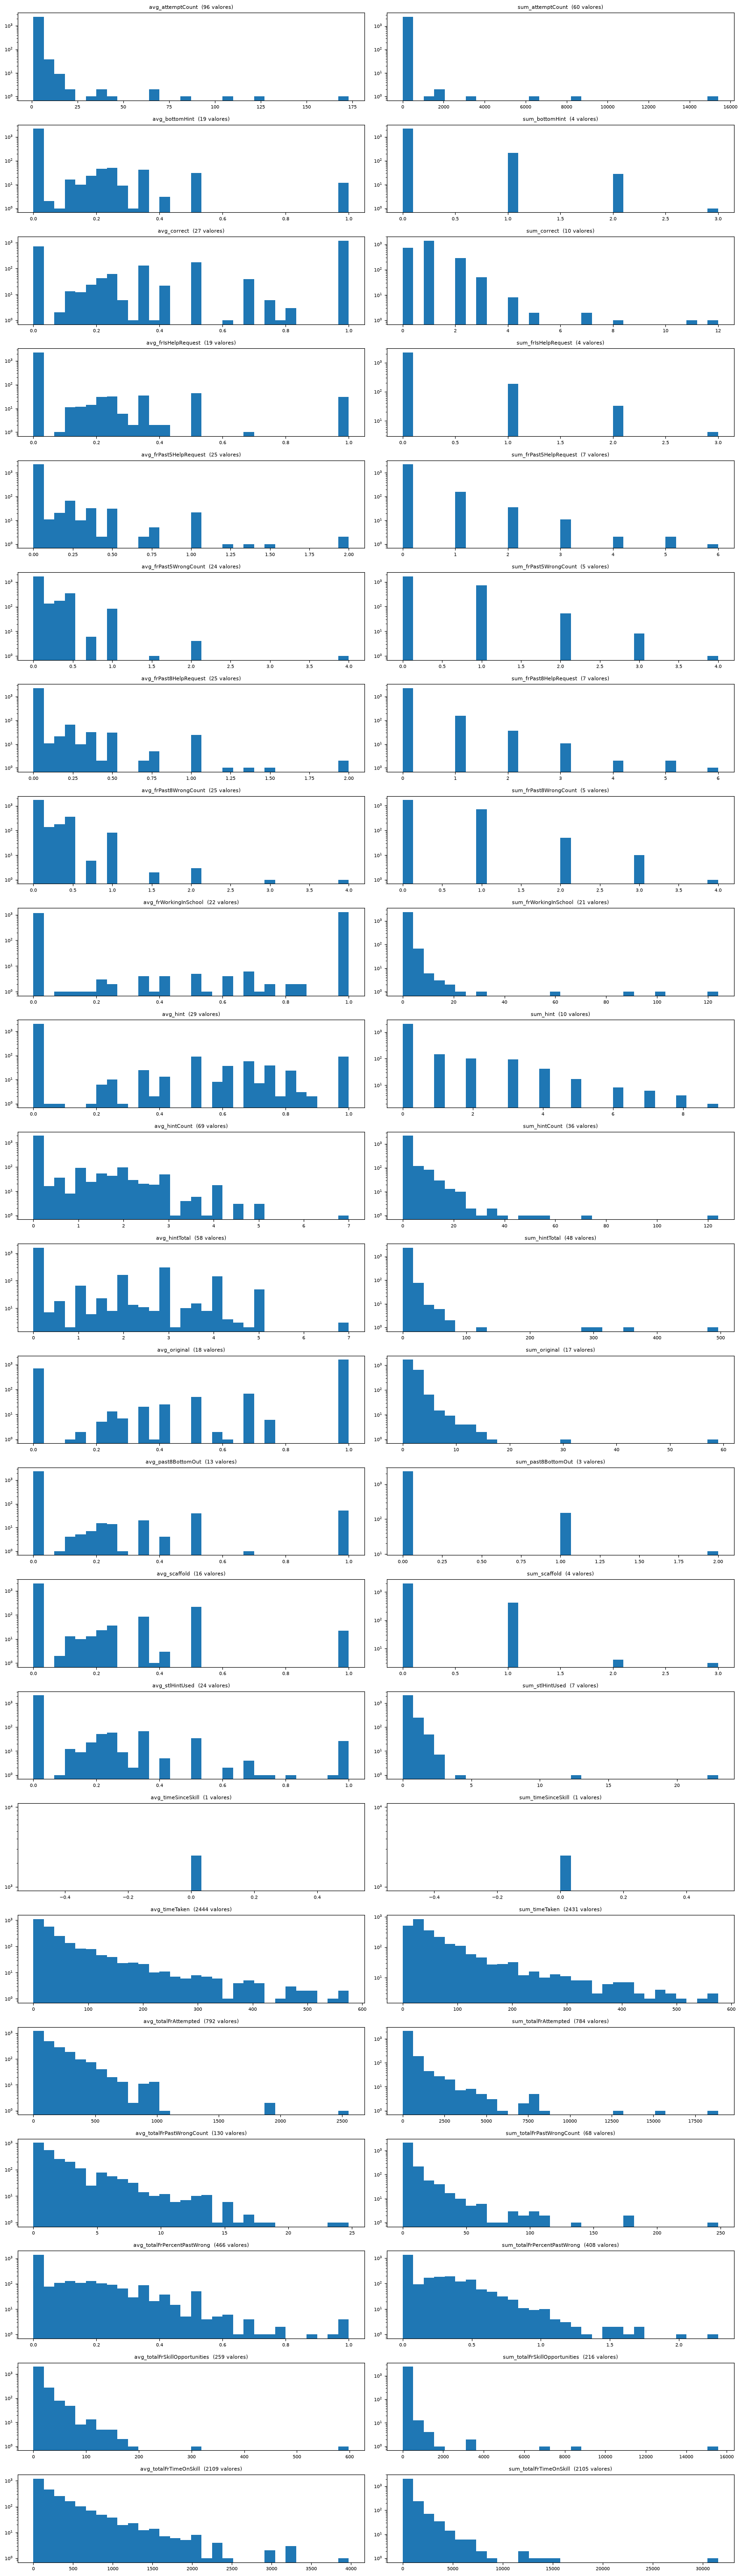

In [12]:
# Vamos a ver cual de avg, max, min, sum, aporta mas info en cada caso para reducir la sobreinformación
# En una primera pasada eliminamos min y max porque no aportan nada nuevo
import matplotlib.pyplot as plt

def hist_features(datos, bases, versiones=("avg", "sum"),
                  bins=30, log_y=True, nombre_png=None):
    fig, ejes = plt.subplots(len(bases), len(versiones), figsize=(16, 2.4 * len(bases)))
    ejes = np.atleast_2d(ejes)
    for i, base in enumerate(bases):
        for j, v in enumerate(versiones):
            ax = ejes[i, j]
            col = f"{v}_{base}"
            if col not in datos.columns:           # por si alguna versión ya se eliminó
                ax.axis("off")
                continue
            ax.hist(datos[col], bins=bins)
            ax.set_title(f"{col}  ({datos[col].nunique()} valores)", fontsize=8)
            ax.tick_params(labelsize=7)
            if log_y:
                ax.set_yscale("log")
    plt.tight_layout()
    if nombre_png:
        plt.savefig(nombre_png, dpi=80, bbox_inches="tight")
    plt.show()

# Las variables base se sacan solas de las columnas de X_train
prefijos = ("avg_", "sum_")
bases = sorted({c.split("_", 1)[1] for c in X_train.columns if c.startswith(prefijos)})
print(len(bases), "variables base:", bases)

# Una sola imagen con todas
hist_features(X_train, bases)

In [13]:
# Aplicaremos log a aquellas features con colas largas mayores a 20
logaritmicas = X_train.columns[X_train.max() > 20].tolist()
print(len(logaritmicas), logaritmicas)

29 ['avg_attemptCount', 'avg_timeTaken', 'avg_totalFrAttempted', 'avg_totalFrPastWrongCount', 'avg_totalFrSkillOpportunities', 'avg_totalFrTimeOnSkill', 'max_attemptCount', 'max_timeTaken', 'max_totalFrAttempted', 'max_totalFrPastWrongCount', 'max_totalFrSkillOpportunities', 'max_totalFrTimeOnSkill', 'min_attemptCount', 'min_timeTaken', 'min_totalFrAttempted', 'min_totalFrPastWrongCount', 'min_totalFrSkillOpportunities', 'min_totalFrTimeOnSkill', 'sum_attemptCount', 'sum_frWorkingInSchool', 'sum_hintCount', 'sum_hintTotal', 'sum_original', 'sum_stlHintUsed', 'sum_timeTaken', 'sum_totalFrAttempted', 'sum_totalFrPastWrongCount', 'sum_totalFrSkillOpportunities', 'sum_totalFrTimeOnSkill']


In [14]:
# Seleccionamso en que casos usaremos solo avg y en cuales tambiés con sum
ambas = ["correct", "attemptCount", "hint", "hintCount", "hintTotal", "bottomHint",
         "past8BottomOut", "stlHintUsed", "frIsHelpRequest",
         "frPast8HelpRequest", "scaffold", "frWorkingInSchool"]
solo_avg = ["timeTaken", "totalFrTimeOnSkill", "frPast8WrongCount",
            "totalFrAttempted", "totalFrSkillOpportunities", "totalFrPastWrongCount",
            "totalFrPercentPastWrong", "original"]
cols_reducida = [f"avg_{v}" for v in ambas + solo_avg] + [f"sum_{v}" for v in ambas]
print(len(cols_reducida), [c for c in cols_reducida if c not in X_train.columns])   

32 []


In [15]:
cols_modelo = cols_reducida + ["urbanicity"]

X_train_red = X_train[cols_modelo]
X_test_red  = X_test[cols_modelo]

#Las cols a tratar en el preprocesamiento
cols_log= [c for c in cols_reducida if X_train_red[c].max() > 20] 
cols_cat = ["urbanicity"] 
cols_num = [c for c in cols_reducida if c not in cols_log] 


In [16]:
from pathlib import Path

data = Path(r"C:\Users\TB Val 03\Desktop\PAULA PROYECTOS\MLproject\data")     
for sub in ["raw", "processed", "train", "test"]:
    (data / sub).mkdir(parents=True, exist_ok=True)

# processed: lo que sale de la limpieza, antes del modelo
processed = df_modelo[cols_modelo + ["user_id", "target"]]
processed.to_csv(data / "processed" / "clips_procesados.csv", index_label="indice_original")

# train y test: el mismo split que ya hiciste
train = processed.loc[X_train.index]
test  = processed.loc[X_test.index]
train.to_csv(data / "train" / "train.csv", index_label="indice_original")
test.to_csv(data / "test" / "test.csv",   index_label="indice_original")

print(processed.shape, train.shape, test.shape)     

(3093, 35) (2474, 35) (619, 35)


In [17]:
X_train_red.describe().T

,count,mean,std,min,25%,50%,75%,max
avg_correct,2474.0,0.575096,0.444704,0.000,0.000000,0.666667,1.000000,1.0000
avg_attemptCount,2474.0,2.125594,5.776638,1.000,1.000000,1.000000,2.000000,173.0000
avg_hint,2474.0,0.112079,0.266069,0.000,0.000000,0.000000,0.000000,1.0000
avg_hintCount,2474.0,0.390424,0.869590,0.000,0.000000,0.000000,0.000000,7.0000
avg_hintTotal,2474.0,0.993453,1.504447,0.000,0.000000,0.000000,2.000000,7.0000
avg_bottomHint,2474.0,0.030290,0.109356,0.000,0.000000,0.000000,0.000000,1.0000
avg_past8BottomOut,2474.0,0.036048,0.159627,0.000,0.000000,0.000000,0.000000,1.0000
avg_stlHintUsed,2474.0,0.044196,0.143268,0.000,0.000000,0.000000,0.000000,1.0000
avg_frIsHelpRequest,2474.0,0.035251,0.138306,0.000,0.000000,0.000000,0.000000,1.0000
avg_frPast8HelpRequest,2474.0,0.034853,0.148778,0.000,0.000000,0.000000,0.000000,2.0000


Definitivamente, nos disponemos a diseñar el pipeline en el que 
1. Preprocesaremos (2 preprocesadores dependiendo de las necesidades del modelo)
    - Aplicaremos logs a cols_log (cuando necesario)
    - Aplicaremos standard scaler a todas (cuando necesario)
    - Aplicaremos onehotencoder a urbanicity
    - Aplicaremos labelencoder para codificar el target
2. Probaremos modelos
    - Regresión logística (necesita escalado)
    - Random forest
    - Lightgbm


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

#------PREPROCESAMIENTO PARA REG.LOGÍSTICA-------------
pipeline_log_scal = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
]).set_output(transform="pandas")

pipeline_cat= Pipeline([
    ("onehot", OneHotEncoder( sparse_output=False, handle_unknown="ignore"))
])

pipeline_scal = Pipeline([("scaler", StandardScaler())])

prep_rl = ColumnTransformer(
    [
        ("log_scal", pipeline_log_scal, cols_log),          # grupo A
        ("num",      pipeline_scal,      cols_num),         # grupo B
        ("cat",      pipeline_cat,      cols_cat),    # grupo C
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")


In [19]:
X_train_prep_rl = prep_rl.fit_transform(X_train_red)
print(X_train_prep_rl.shape)
print("nulos:", X_train_prep_rl.isna().sum().sum())
print(X_train_prep_rl[cols_log + cols_num].mean().abs().max().round(6)) 

(2474, 35)
nulos: 0
0.0


In [20]:
#-----------PREPROCESAMIENTO ÁRBOLES---------------
prep_arbol = ColumnTransformer(
    [
        ("num", "passthrough", cols_log + cols_num),   
        ("cat", pipeline_cat, cols_cat)            
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

X_train_prep_arbol = prep_arbol.fit_transform(X_train_red)
print(X_train_prep_arbol.shape, "| nulos:", X_train_prep_arbol.isna().sum().sum())
print(X_train_prep_arbol[cols_num].equals(X_train_red[cols_num]))

(2474, 35) | nulos: 0
True


In [21]:
#%pip install lightgbm

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

modelos = {
    "Logistic Regression": (prep_rl, LogisticRegression(max_iter=10000, random_state=42)),
    "Random Forest": (prep_arbol, RandomForestClassifier(random_state=42)),
    "LightGBM": (prep_arbol, LGBMClassifier(random_state=42, verbose=-100))
}

target_enc = LabelEncoder()
y_train_num = target_enc.fit_transform(y_train)

metricas_cv = {}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for nombre, (prep, modelo) in modelos.items():
    pipe = Pipeline([("prep", prep), ("modelo", modelo)])
    metricas_cv[nombre] = cross_val_score(pipe, X_train_red, y_train_num, groups=g_train,
                                          cv=cv, scoring="f1_macro", n_jobs=-1).mean()

pd.Series(metricas_cv).sort_values(ascending=False) 

Logistic Regression    0.320216
LightGBM               0.288881
Random Forest          0.288338
dtype: float64

In [23]:

from sklearn.metrics import make_scorer, f1_score, classification_report

#---------------OPTIMIZACIÓN DE PARAMS-------------------
pipe = Pipeline([
    ("prep", prep_rl),                 # valor inicial: el grid lo cambia
    ("modelo", LogisticRegression())
])

param_grid = [
    {
        "prep":   [prep_rl],
        "modelo": [LogisticRegression(max_iter=10000, random_state=42)],
        "modelo__C": [0.01, 0.1, 1, 10],
        "modelo__class_weight": [None, "balanced"],
    },
    {
        "prep":   [prep_arbol],
        "modelo": [RandomForestClassifier(random_state=42, n_jobs=1)],
        "modelo__n_estimators": [200, 500],
        "modelo__max_depth": [None, 5, 10],
        "modelo__min_samples_leaf": [1, 5],
        "modelo__class_weight": [None, "balanced","balanced_subsample"],
    },
    {
        "prep":   [prep_arbol],
        "modelo": [LGBMClassifier(random_state=42, verbose=-1, n_jobs=1)],
        "modelo__n_estimators": [100, 250],
        "modelo__learning_rate": [0.05, 0.1],
        "modelo__max_depth": [3, 6],
        "modelo__min_child_samples": [10, 20],
        "modelo__class_weight": [None, "balanced"],
    },
]

# scoring = {"roc_auc_ovr": "roc_auc_ovr",
#            "f1_macro": "f1_macro",
#            "balanced_acc": "balanced_accuracy"}

#Para que se centre en detecter las emociones menos comunes: boredom, confusion y frutation
f1_raras = make_scorer(f1_score, average="macro", labels=[0, 2, 3], zero_division=0)

scoring = {"f1_raras": f1_raras, "roc_auc_ovr": "roc_auc_ovr", "f1_macro": "f1_macro"}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring=scoring,
                    refit="f1_raras", n_jobs=-1)
grid.fit(X_train_red, y_train_num, groups=g_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [LogisticRegre...ndom_state=42)], 'modelo__C': [0.01, 0.1, ...], 'modelo__class_weight': [None, 'balanced'], 'prep': [ColumnTransfo...mes_out=False)]}, {'modelo': [RandomForestC...ndom_state=42)], 'modelo__class_weight': [None, 'balanced', ...], 'modelo__max_depth': [None, 5, ...], 'modelo__min_samples_leaf': [1, 5], ...}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f1_macro': 'f1_macro', 'f1_raras': make_scorer(f...ro_division=0), 'roc_auc_ovr': 'roc_auc_ovr'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_raras'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :clas

In [24]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

print(type(grid.best_params_["modelo"]).__name__)     # confirma que es LogisticRegression
print(target_enc.classes_)                                    # orden de las clases

pred_train = cross_val_predict(clone(grid.best_estimator_), X_train_red, y_train_num,
                         groups=g_train, cv=cv, n_jobs=-1)

print(classification_report(y_train_num, pred_train, target_names=target_enc.classes_, zero_division=0))

LogisticRegression
['boredom' 'concentration' 'confusion' 'frustration']
               precision    recall  f1-score   support

      boredom       0.26      0.44      0.33       247
concentration       0.94      0.60      0.73      2041
    confusion       0.10      0.44      0.16        97
  frustration       0.11      0.37      0.17        89

     accuracy                           0.57      2474
    macro avg       0.35      0.46      0.35      2474
 weighted avg       0.81      0.57      0.65      2474



In [25]:
grid.best_params_

{'modelo': LogisticRegression(max_iter=10000, random_state=42),
 'modelo__C': 1,
 'modelo__class_weight': 'balanced',
 'prep': ColumnTransformer(transformers=[('log_scal',
                                  Pipeline(steps=[('log',
                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                       func=<ufunc 'log1p'>)),
                                                  ('scaler', StandardScaler())]),
                                  ['avg_attemptCount', 'avg_timeTaken',
                                   'avg_totalFrTimeOnSkill',
                                   'avg_totalFrAttempted',
                                   'avg_totalFrSkillOpportunities',
                                   'avg_totalFrPastWrongCount',
                                   'sum_attemptCount', 'sum_hintCount',
                                   '...
                                   'avg_frWorkingInSch

In [26]:
from sklearn.metrics import roc_auc_score
proba = cross_val_predict(clone(grid.best_estimator_), X_train_red, y_train_num,
                          groups=g_train, cv=cv, method="predict_proba", n_jobs=-1)

print("AUC validación:", round(roc_auc_score(y_train_num, proba, multi_class="ovr", average="macro" ), 3))
print("F1 macro validación:", round(f1_score(y_train_num, pred_train, average="macro"), 3))
print("f1_raras   :", round(f1_score(y_train_num, pred_train, labels=[0, 2, 3], average="macro", zero_division=0), 3))

AUC validación: 0.73
F1 macro validación: 0.345
f1_raras   : 0.217


In [27]:
from sklearn.metrics import confusion_matrix

print(target_enc.classes_)
print(confusion_matrix(y_train_num, pred_train))

['boredom' 'concentration' 'confusion' 'frustration']
[[ 109   45   49   44]
 [ 272 1220  341  208]
 [  18   12   43   24]
 [  20   19   17   33]]


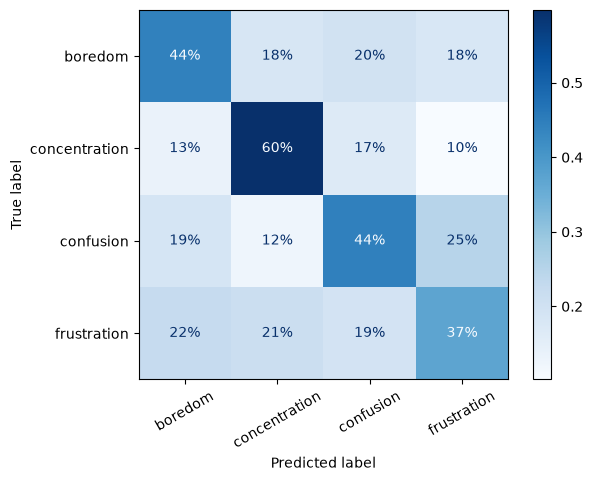

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
disp=ConfusionMatrixDisplay.from_predictions(
    y_train_num, pred_train,
    display_labels=target_enc.classes_,
    normalize="true", values_format=".0%",
    cmap="Blues", xticks_rotation=30)
plt.show()
disp.figure_.savefig("../imgs/matriz_confusion_val_multiclase.png", dpi=300, bbox_inches="tight")

In [29]:
#---------GUARDADO DEL MEJOR MODELO----------------
import joblib
import os

dir_modelos = "C:/Users/TB Val 03/Desktop/PAULA PROYECTOS/MLproject/modelos"
joblib.dump(grid.best_estimator_, os.path.join(dir_modelos, "final_model_multiclase.pkl"))



['C:/Users/TB Val 03/Desktop/PAULA PROYECTOS/MLproject/modelos\\final_model_multiclase.pkl']

In [30]:
# --------------------- FASE DE PREDICCIÓN--------------------------

from sklearn.metrics import roc_auc_score

mejor = grid.best_estimator_           # ya reentrenado con todo X_train_red
y_test_num = target_enc.transform(y_test)      # transform, NO fit_transform!!!!!

pred_test  = mejor.predict(X_test_red)
proba_test = mejor.predict_proba(X_test_red)

print(classification_report(y_test_num, pred_test, target_names=target_enc.classes_, zero_division=0))
print("f1_raras   :", round(f1_score(y_test_num, pred_test, labels=[0, 2, 3], average="macro", zero_division=0), 3))
print("f1_macro   :", round(f1_score(y_test_num, pred_test, average="macro"), 3))
print("roc_auc_ovr:", round(roc_auc_score(y_test_num, proba_test, multi_class="ovr"), 3))

               precision    recall  f1-score   support

      boredom       0.23      0.38      0.29        61
concentration       0.95      0.60      0.74       511
    confusion       0.12      0.58      0.20        24
  frustration       0.12      0.43      0.19        23

     accuracy                           0.58       619
    macro avg       0.36      0.50      0.36       619
 weighted avg       0.82      0.58      0.65       619

f1_raras   : 0.227
f1_macro   : 0.355
roc_auc_ovr: 0.742


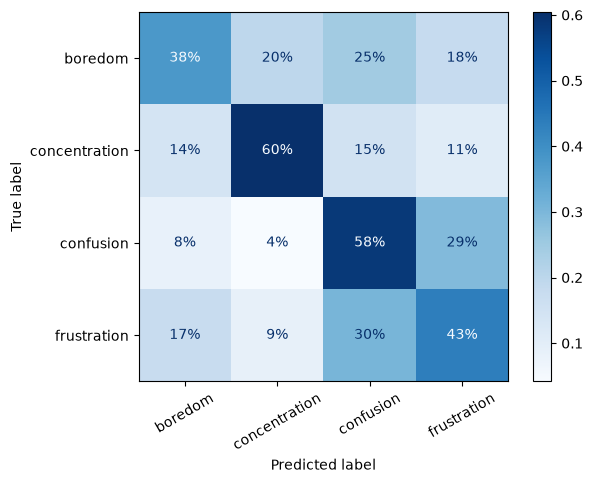

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
disp2=ConfusionMatrixDisplay.from_predictions(
    y_test_num, pred_test,
    display_labels=target_enc.classes_,
    normalize="true", values_format=".0%",
    cmap="Blues", xticks_rotation=30)
plt.show()
disp2.figure_.savefig("../imgs/matriz_confusion_test_multiclase.png", dpi=300, bbox_inches="tight")